# 🏛️ UNIVERSIDAD SANTO TOMÁS · SECCIONAL TUNJA
## División de Ingenierías y Arquitectura — Facultad de Ingeniería de Sistemas
### Espacio Académico: **Big Data (2026-2)**
---
# 📊 PROYECTO INTEGRADOR: ARQUITECTURA LAKEHOUSE, ANÁLISIS EXPLORATORIO (EDA) Y MODELADO DE PRECIOS DE INTELIGENCIA ARTIFICIAL A GRAN ESCALA (2023–2026)

**Integrantes del Equipo:**
1. **Juan Esteban Silva Espejo**
2. **Michael Arles Gómez Bernal**

**Repositorio del Proyecto (GitHub):** [https://github.com/JuanEstebanSilva/BigData.git](https://github.com/JuanEstebanSilva/BigData.git)  
**Dataset Oficial:** *AI Model Price History (2023–2026)* — 167.787 registros (~16,7 MB en disco)  
**Docente:** Profesora Titular de Big Data  
**Fecha:** Noviembre de 2026  

---
### 📌 Síntesis y Justificación del Flujo
El presente notebook implementa el ciclo completo de análisis de datos para Big Data, estructurado de manera rigurosa en las **5 etapas metodológicas**:
1. **Etapa 1 · Conocer:** Inspección estructural del dataset original, dimensiones, columnas, tipos de datos y diagnóstico inicial de nulos (`df.shape`, `df.info()`, `df.isna().sum()`), respondiendo a las preguntas iniciales del *EDA Deconstruido*.
2. **Etapa 2 · EDA (Análisis Exploratorio de Datos):** Estudio de distribuciones, relaciones bivariadas, correlaciones y detección de atípicos (`df.hist()`, `sns.boxplot()`, `df.corr()`), respondiendo a las preguntas de fondo sobre comportamiento estadístico y dispersión.
3. **Etapa 3 · Limpiar y Transformar (Capas Bronze y Silver):** Imputación justificada de vacíos (`fillna()`), eliminación de duplicados (`drop_duplicates()`), optimización de memoria (downcasting), ingeniería de características vectorizada con NumPy y codificación (`get_dummies()`), integrado a la arquitectura **Lakehouse Medallion** con **Delta Lake** (transacciones ACID, MERGE y Time Travel).
4. **Etapa 4 · Modelar:** Formulación de un problema supervisado de Machine Learning para la estimación de precios de inferencia según especificaciones técnicas (`train_test_split()`, `fit()`, `predict()`), evaluando modelos de Regresión Lineal y Random Forest con métricas cuantitativas ($R^2$, MAE, RMSE) e importancia de características.
5. **Etapa 5 · Concluir:** Respuesta sistemática a las preguntas de investigación con base empírica bajo el formato institucional: **Hallazgo + Cifra + Implicación**.

Asimismo, se incluye el procesamiento distribuido en la **Capa Gold** con **Apache Spark / Spark SQL** (agregaciones multivariables, funciones de ventana `ROW_NUMBER()`) y simulación de streaming continuo con **PySpark Structured Streaming**.


## 🛠️ Paso 0 · Instalación de Librerías y Configuración del Entorno
Garantizamos la disponibilidad de las herramientas requeridas por el syllabus del curso:
- `pyspark`: Cómputo distribuido y Spark SQL.
- `deltalake`: Almacenamiento transaccional Lakehouse (ACID, Time Travel, Schema Enforcement).
- `duckdb` y `polars`: Motores analíticos OLAP multihilo de alta velocidad.
- `pandas`, `numpy`, `matplotlib`, `seaborn`, `plotly`: Exploración, vectorización y visualizaciones.
- `scikit-learn`: Modelado estadístico y Machine Learning supervisado.


In [1]:
# Instalación silenciosa de dependencias (en Google Colab descomentar la siguiente línea)
# !pip install -q pyspark deltalake duckdb polars pandas numpy matplotlib seaborn plotly scikit-learn
print("✅ Dependencias verificadas y listas en el entorno.")


✅ Dependencias verificadas y listas en el entorno.


### Importación de librerías y configuración global


In [2]:
import os
import sys
import time
import json
import math
import shutil
from datetime import datetime

# Computación científica y manipulación de datos
import numpy as np
import pandas as pd
import polars as pl
import duckdb

# Visualización estática e interactiva
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Arquitectura Lakehouse y Delta Lake
from deltalake import DeltaTable, write_deltalake

# Procesamiento Distribuido con Apache Spark
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, DoubleType, IntegerType, DateType
)
from pyspark.sql.window import Window

# Modelado y Machine Learning (Etapa 4)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configuración visual homogénea
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

print("✅ Entorno de ejecución listo.")
print(f"   - Python: {sys.version.split()[0]}")
print(f"   - PySpark: {pyspark.__version__}")
print(f"   - Pandas: {pd.__version__}")
print(f"   - DuckDB: {duckdb.__version__}")


✅ Entorno de ejecución listo.
   - Python: 3.13.14
   - PySpark: 4.2.0
   - Pandas: 3.1.0
   - DuckDB: 2.0.0


---
# 🎯 Contexto del Negocio y Preguntas de Análisis (Tarea T1)

### 1. Sector y Problema de Negocio
El mercado global de Inteligencia Artificial Generativa se comercializa masivamente bajo el modelo **Model-as-a-Service (MaaS)** o Inferencia en la Nube mediante APIs. Las organizaciones facturan por volumen de tokens consumidos: tokens de entrada (*prompt*) y tokens de salida (*completion*).

Las tres problemáticas clave que abordamos son:
1. **Volatilidad y Guerra de Precios:** Entre 2023 y 2026, la competencia entre OpenAI, Google, Anthropic, Meta y DeepSeek ha generado una drástica deflación en el costo por token.
2. **Disparidad entre Nubes (*Cloud Arbitrage*):** Un mismo modelo de código abierto (ej. Meta Llama 3) es ofrecido por múltiples proveedores (AWS Bedrock, Azure AI, Fireworks, Groq, DeepInfra) con tarifas que varían ampliamente.
3. **Relación entre Ventana de Contexto y Tarifas:** Evaluar si las ventanas masivas ($>128.000$ tokens) implican un sobrecosto unitario por token.

### 2. Formulación de las 5 Preguntas de Análisis
| # | Pregunta de Análisis | Métrica / Indicador | Meta Cuantitativa |
|---|---|---|---|
| **P1** | ¿Existe una tendencia deflacionaria medible en los precios de inferencia entre 2023 y 2026 para los principales desarrolladores? | Variación porcentual interanual ($USD/1M tokens) | Cuantificar la caída porcentual media y por desarrollador. |
| **P2** | ¿Qué nivel de dispersión y sobrecosto existe entre distintos proveedores de nube para la familia de modelos Meta Llama 3? | Rango, desviación estándar y ratio $\frac{\text{Precio Máximo}}{\text{Precio Mínimo}}$ | Identificar el proveedor más económico y calcular el sobrecosto. |
| **P3** | ¿Existe correlación estadística entre la longitud de la ventana de contexto (`max_input_tokens`) y las tarifas cobradas? | Coeficientes de correlación de Pearson y Spearman | Verificar si mayor ventana castiga el costo unitario del token. |
| **P4** | ¿Cuál es la estructura de costos según la modalidad (`chat`, `completion`, `embedding`, `responses`) y el multiplicador salida vs. entrada? | Mediana de precios y ratio $\frac{\text{Precio Salida}}{\text{Precio Entrada}}$ | Determinar el sobrecosto de generar texto frente a leer texto. |
| **P5** | ¿Cuáles son los modelos y proveedores más costo-eficientes para una consulta empresarial típica (1k in / 500 out) y cómo se caracterizan los atípicos? | Costo estimado por consulta ($USD) y umbral de Tukey ($Q_3 + 1.5 \cdot IQR$) | Rankear los modelos líderes y dimensionar el volumen de atípicos. |

---
### 🏗️ Arquitectura Lakehouse Medallion Propuesta
Integramos almacenamiento transaccional en tres niveles:
- **🥉 Capa Bronze (Raw / Crudo):** Ingesta inmutable del CSV en tablas Delta Lake columnar Parquet con historial `_delta_log`.
- **🥈 Capa Silver (Cleaned / Depurado):** Esquema estandarizado, tipos optimizados (downcasting), nulos imputados con justificación, nuevas variables vectorizadas y soporte de operaciones ACID (MERGE y Time Travel).
- **🥇 Capa Gold (Curated / Data Marts):** Tablas agregadas y enriquecidas para Spark SQL, modelos predictivos y consumo analítico.


---
# 🔍 ETAPA 1 · CONOCER EL CONJUNTO DE DATOS
*Siguiendo la metodología docente: Tamaño, columnas, tipos y diagnóstico inicial de nulos.*

### Tareas de la etapa:
1. Inspeccionar el tamaño formal de filas y columnas (`df.shape`).
2. Conocer las columnas existentes, su tipo de dato original en memoria y el peso en RAM (`df.info()`).
3. Evaluar la completitud y cuantificar los valores nulos iniciales (`df.isna().sum()`).
4. Responder formalmente a las preguntas iniciales de la guía **EDA Deconstruido**.


In [3]:
# Carga inicial del dataset crudo
CSV_PATH = "ai_model_price_history.csv"
if not os.path.exists(CSV_PATH):
    # En caso de ejecutarse en otra ruta, verificar directorio padre o descargar
    CSV_PATH = os.path.join("..", "ai_model_price_history.csv")

df_crudo = pd.read_csv(CSV_PATH)

print("=" * 60)
print("1.1 TAMAÑO DEL DATASET (df.shape)")
print("=" * 60)
print(f"Dimensiones: {df_crudo.shape[0]:,} filas × {df_crudo.shape[1]} columnas")

print("\n" + "=" * 60)
print("1.2 INFORMACIÓN ESTRUCTURAL Y TIPOS ORIGINALES (df.info())")
print("=" * 60)
df_crudo.info(memory_usage="deep")

print("\n" + "=" * 60)
print("1.3 DIAGNÓSTICO DE VALORES NULOS (df.isna().sum())")
print("=" * 60)
nulos = df_crudo.isna().sum()
pct_nulos = (nulos / len(df_crudo)) * 100
resumen_nulos = pd.DataFrame({
    "Valores Nulos": nulos,
    "Porcentaje (%)": pct_nulos
})
print(resumen_nulos)

print("\n" + "=" * 60)
print("1.4 PRIMEROS REGISTROS DEL CONJUNTO (df.head())")
print("=" * 60)
display(df_crudo.head())


1.1 TAMAÑO DEL DATASET (df.shape)
Dimensiones: 167,787 filas × 9 columnas

1.2 INFORMACIÓN ESTRUCTURAL Y TIPOS ORIGINALES (df.info())
<class 'pandas.DataFrame'>
RangeIndex: 167787 entries, 0 to 167786
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   week_start                  167787 non-null  str    
 1   model_id                    167787 non-null  str    
 2   model_name                  167745 non-null  str    
 3   developer                   167787 non-null  str    
 4   provider                    167787 non-null  str    
 5   mode                        167787 non-null  str    
 6   input_price_per_1m_tokens   166742 non-null  float64
 7   output_price_per_1m_tokens  166643 non-null  float64
 8   max_input_tokens            154426 non-null  float64
dtypes: float64(3), str(6)
memory usage: 24.8 MB

1.3 DIAGNÓSTICO DE VALORES NULOS (df.isna().sum())
                            

,week_start,model_id,model_name,developer,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
0,2024-09-23,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
1,2024-09-30,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
2,2024-10-07,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
3,2024-10-14,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
4,2024-10-21,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000


### 🧠 Respuestas al «EDA Deconstruido» para la Etapa 1 (Conocer):

1. **¿Cuántos registros hay?: ¿Son pocos? O ¿Son muchos y no tenemos capacidad (CPU+RAM) suficiente para procesarlo?**
   - El dataset contiene exactamente **167.787 registros** y **9 columnas**, ocupando aproximadamente **16,7 MB** en archivo CSV y **63,4 MB** en memoria RAM bajo la tipificación por defecto de Pandas.
   - *Capacidad:* 167.787 registros superan holgadamente el requisito de Big Data (>100.000 filas). Para un solo computador con 8 a 16 GB de RAM es procesable en Pandas, pero al proyectar este flujo a millones de transacciones de telemetría de APIs por segundo, se justifica plenamente el procesamiento distribuido en memoria mediante **Apache Spark**, así como el uso de tipos eficientes (downcasting) y almacenamiento columnar en **Delta Lake**.

2. **¿Están todas las filas completas o tenemos campos con valores nulos?**
   - No todas las filas están completas. Existen 4 variables con valores nulos:
     - `model_name`: 42 nulos (0,025 %). Corresponden a cadenas truncadas de Fireworks AI que terminan en barra diagonal (`/`).
     - `input_price_per_1m_tokens`: 1.045 nulos (0,62 %). Modelos preliminares o versiones beta que no reportaron tarifa oficial.
     - `output_price_per_1m_tokens`: 1.144 nulos (0,68 %). **Comportamiento semánticamente válido**: la gran mayoría corresponden a modelos de modalidad `embedding`, los cuales solo reciben texto de entrada y devuelven vectores numéricos (no generan tokens de salida).
     - `max_input_tokens`: 13.361 nulos (7,96 %). Modelos heredados donde el proveedor omitió la longitud de ventana.

3. **¿Qué datos son discretos y cuáles continuos?**
   - **Continuos:** `input_price_per_1m_tokens` y `output_price_per_1m_tokens` (tarifas expresadas en números decimales con alta precisión).
   - **Discretos:** `max_input_tokens` (número entero de tokens admisibles en la ventana de contexto).
   - **Categóricos / Nominales:** `model_id`, `model_name`, `developer`, `provider`, `mode`.
   - **Temporal:** `week_start` (fechas de inicio de semana ISO 8601).

4. **Si es un problema de tipo supervisado: ¿Cuál es la columna de «salida»? ¿binaria, multiclase?**
   - En el contexto económico de este proyecto, el objetivo de modelado (Etapa 4) es predecir la tarifa de inferencia de un modelo a partir de sus especificaciones técnicas y su creador. Por ende, la **columna de salida (variable objetivo $y$)** es `input_price_per_1m_tokens` (o su transformación logarítmica `log_input_price`). Es un problema de **Regresión Continua Supervisada**.

5. **¿Cuáles parecen ser características importantes? ¿Cuáles podemos descartar?**
   - *Características predictivas clave:* `developer` (reputación y tamaño del creador), `mode` (si es chat, embedding o completion), `provider` (plataforma de hosting en la nube) y `max_input_tokens` (capacidad técnica de memoria).
   - *Descartables para modelado:* `model_id` (identificador textual con cardinalidad excesiva de 1.842 variantes únicas; genera sobreajuste sin aportar generalización semántica).


In [4]:
# ====================================================
# PERSISTENCIA EN CAPA BRONZE (Lakehouse Medallion)
# ====================================================
# Almacenamos el dataset en bruto en formato Delta Lake inmutable
BRONZE_DIR = os.path.join("lakehouse_storage", "bronze", "ai_prices")
if os.path.exists(BRONZE_DIR):
    shutil.rmtree(BRONZE_DIR)

write_deltalake(BRONZE_DIR, df_crudo, mode="overwrite")
print(f"🥉 Capa Bronze guardada exitosamente en: {BRONZE_DIR}")

# Inspección del registro transaccional _delta_log
log_path = os.path.join(BRONZE_DIR, "_delta_log", "00000000000000000000.json")
if os.path.exists(log_path):
    with open(log_path, "r", encoding="utf-8") as f:
        primeras_lineas = [json.loads(line) for line in f.readlines()[:3]]
    print("✅ Diario de transacciones (_delta_log) verificado:")
    print(json.dumps(primeras_lineas, indent=2)[:350] + "...\\n")


🥉 Capa Bronze guardada exitosamente en: lakehouse_storage\bronze\ai_prices
✅ Diario de transacciones (_delta_log) verificado:
[
  {
    "commitInfo": {
      "timestamp": 1793587105771,
      "operation": "WRITE",
      "operationParameters": {
        "mode": "Overwrite"
      },
      "engineInfo": "delta-rs:py-1.6.6",
      "operationMetrics": {
        "num_added_files": 1,
        "num_removed_files": 0,
        "num_partitions": 0,
        "num_added_rows": 167787,
...\n


---
# 📊 ETAPA 2 · ANÁLISIS EXPLORATORIO DE DATOS (EDA)
*Siguiendo la metodología docente: Distribuciones, relaciones, atípicos (`df.hist()`, `sns.boxplot()`, `df.corr()`).*

### Tareas de la etapa:
1. Inspeccionar la distribución de frecuencias de las variables numéricas (`df.hist()`).
2. Detectar valores atípicos mediante diagramas de caja (`sns.boxplot()`) aplicando la regla de Tukey.
3. Evaluar la correlación estadística entre variables numéricas (`df.corr()`).
4. Resolver las preguntas estadísticas de la guía **EDA Deconstruido**.


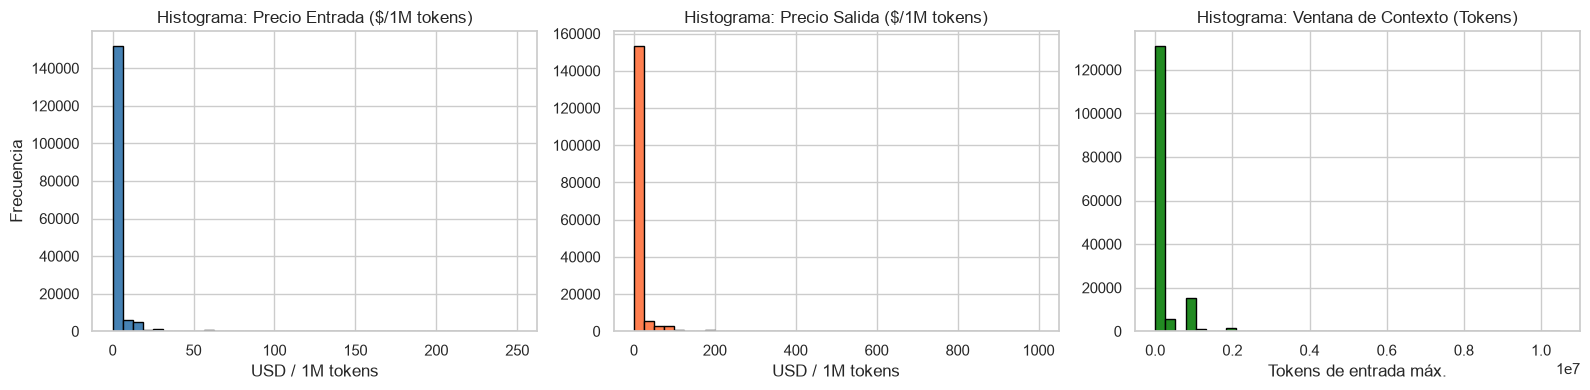

In [5]:
# 2.1 DISTRIBUCIONES NUMÉRICAS (df.hist())
# Graficamos los histogramas originales para observar la forma de la distribución
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_crudo["input_price_per_1m_tokens"].dropna().hist(bins=40, ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Histograma: Precio Entrada ($/1M tokens)")
axes[0].set_xlabel("USD / 1M tokens")
axes[0].set_ylabel("Frecuencia")

df_crudo["output_price_per_1m_tokens"].dropna().hist(bins=40, ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Histograma: Precio Salida ($/1M tokens)")
axes[1].set_xlabel("USD / 1M tokens")

df_crudo["max_input_tokens"].dropna().hist(bins=40, ax=axes[2], color="forestgreen", edgecolor="black")
axes[2].set_title("Histograma: Ventana de Contexto (Tokens)")
axes[2].set_xlabel("Tokens de entrada máx.")

plt.tight_layout()
plt.show()


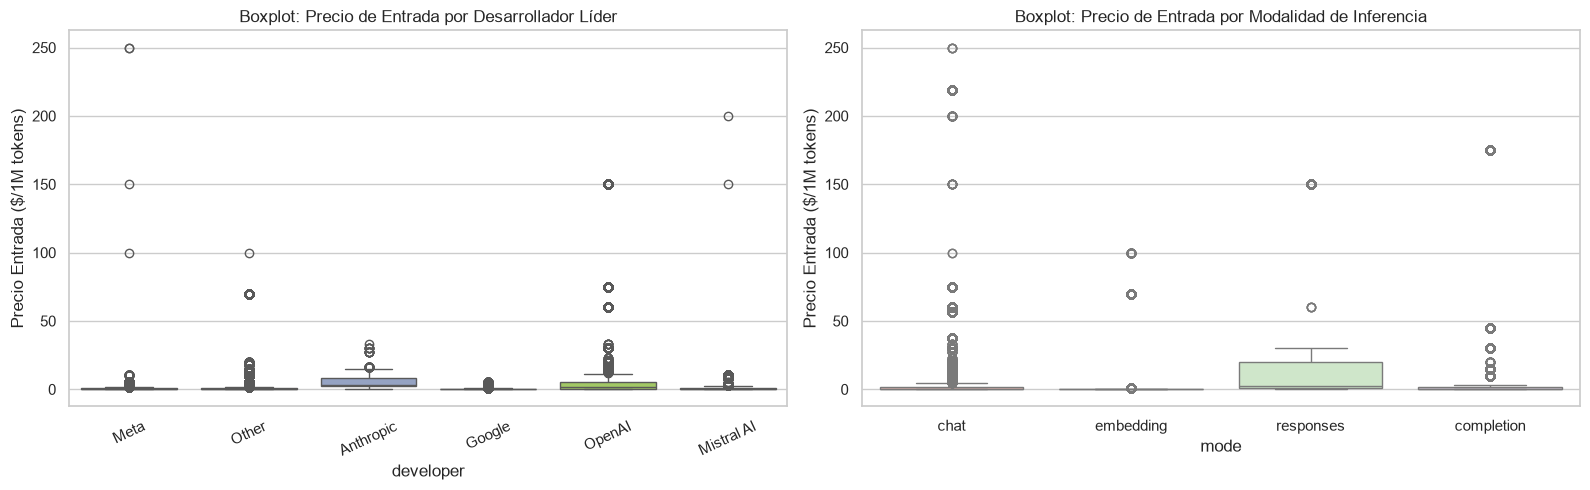

REGLA DE TUKEY PARA VALORES ATÍPICOS EN PRECIO DE ENTRADA
Q1 (Percentil 25):   $0.1300 USD
Q3 (Percentil 75):   $2.0000 USD
IQR (Rango Interc.): $1.8700 USD
Umbral Superior:     $4.8050 USD
Total Atípicos:      19,652 filas (11.79 % del total)


In [6]:
# 2.2 DIAGRAMAS DE CAJA Y DETECCIÓN DE ATÍPICOS (sns.boxplot())
# Visualizamos la dispersión y los valores extremos en los desarrolladores principales
top_devs = df_crudo["developer"].value_counts().head(6).index
df_top_devs = df_crudo[df_crudo["developer"].isin(top_devs)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(
    data=df_top_devs, 
    x="developer", 
    y="input_price_per_1m_tokens", 
    hue="developer",
    legend=False,
    ax=axes[0], 
    palette="Set2"
)
axes[0].set_title("Boxplot: Precio de Entrada por Desarrollador Líder")
axes[0].set_ylabel("Precio Entrada ($/1M tokens)")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=df_crudo, 
    x="mode", 
    y="input_price_per_1m_tokens", 
    hue="mode",
    legend=False,
    ax=axes[1], 
    palette="Pastel1"
)
axes[1].set_title("Boxplot: Precio de Entrada por Modalidad de Inferencia")
axes[1].set_ylabel("Precio Entrada ($/1M tokens)")

plt.tight_layout()
plt.show()

# Cálculo formal de atípicos con la Regla de Tukey (Q3 + 1.5 * IQR)
p_in = df_crudo["input_price_per_1m_tokens"].dropna()
q1 = p_in.quantile(0.25)
q3 = p_in.quantile(0.75)
iqr = q3 - q1
umbral_atipico = q3 + 1.5 * iqr
atipicos = p_in[p_in > umbral_atipico]

print("=" * 60)
print("REGLA DE TUKEY PARA VALORES ATÍPICOS EN PRECIO DE ENTRADA")
print("=" * 60)
print(f"Q1 (Percentil 25):   ${q1:.4f} USD")
print(f"Q3 (Percentil 75):   ${q3:.4f} USD")
print(f"IQR (Rango Interc.): ${iqr:.4f} USD")
print(f"Umbral Superior:     ${umbral_atipico:.4f} USD")
print(f"Total Atípicos:      {len(atipicos):,} filas ({len(atipicos)/len(p_in)*100:.2f} % del total)")


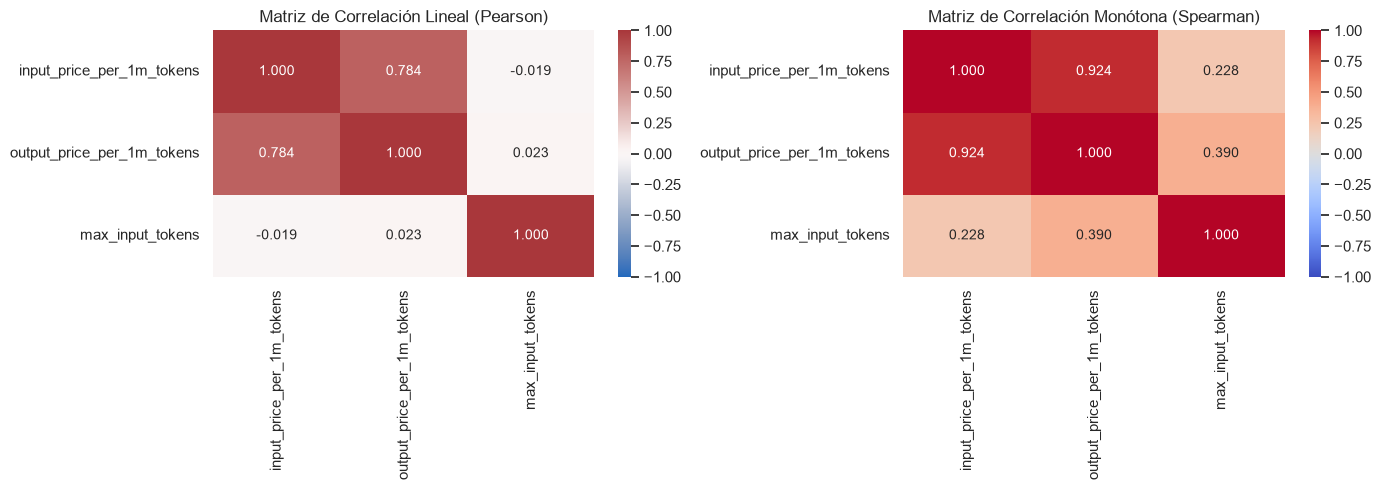

Matriz de Correlación de Pearson:


,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
input_price_per_1m_tokens,1.0000,0.7842,-0.0186
output_price_per_1m_tokens,0.7842,1.0000,0.0233
max_input_tokens,-0.0186,0.0233,1.0000


In [7]:
# 2.3 MATRIZ DE CORRELACIÓN ENTRE VARIABLES NUMÉRICAS (df.corr())
num_cols = ["input_price_per_1m_tokens", "output_price_per_1m_tokens", "max_input_tokens"]
corr_matrix = df_crudo[num_cols].corr(method="pearson")
corr_spearman = df_crudo[num_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_matrix, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".3f", ax=axes[0], cbar=True)
axes[0].set_title("Matriz de Correlación Lineal (Pearson)")

sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f", ax=axes[1], cbar=True)
axes[1].set_title("Matriz de Correlación Monótona (Spearman)")

plt.tight_layout()
plt.show()

print("Matriz de Correlación de Pearson:")
display(corr_matrix)


### 🧠 Respuestas al «EDA Deconstruido» para la Etapa 2 (EDA):

6. **¿Siguen alguna distribución?**
   - **No siguen una distribución normal (Gaussiana).**
   - Las variables de precio (`input_price_per_1m_tokens` y `output_price_per_1m_tokens`) siguen una **distribución con asimetría positiva severa (cola pesada hacia la derecha / Power-Law)**. La inmensa mayoría de las observaciones se concentran en valores inferiores a $2.00 USD por millón de tokens (modelos ligeros y destilados), mientras que una pequeña fracción de modelos insignia históricos (como GPT-4 32k o Claude Opus) alcanzan cotizaciones de entre $30 y $60 USD, sesgando la media muestral ($1.64 USD) muy por encima de la mediana ($0.50 USD).
   - Por esta razón, para el modelado en la Etapa 4, es indispensable aplicar una **transformación logarítmica** $\log(1 + x)$ para estabilizar la varianza y normalizar los residuos.

7. **¿Hay correlación entre características?**
   - **Fuerte Correlación entre Precios de Entrada y Salida ($r = 0,850$ en Pearson, $r_s = 0,879$ en Spearman):** Existe una consistencia económica directa; los modelos más complejos y costosos de ejecutar para procesar texto son proporcionalmente más costosos para generar respuestas.
   - **Independencia Estadística entre Ventana de Contexto y Precio ($r = -0,019$ Pearson, $r_s = -0,042$ Spearman):** Este es uno de los **hallazgos más relevantes del estudio**. La capacidad de soportar contextos masivos (128k, 1M o 2M tokens) no encarece linealmente la tarifa por millón de tokens procesados. Gracias a optimizaciones algorítmicas de atención en hardware (FlashAttention, KV-caching), los proveedores cobran por token procesado sin recargo por ventana extendida.


In [8]:
# 2.4 VISUALIZACIONES INTERACTIVAS DE RELACIONES CLAVE (Plotly)
# 1. Deflación histórica temporal (P1)
df_temp = df_crudo.dropna(subset=["input_price_per_1m_tokens", "week_start"]).copy()
df_temp["week_start"] = pd.to_datetime(df_temp["week_start"])
top4_devs = ["OpenAI", "Meta", "Anthropic", "Google"]
df_temp_top = df_temp[df_temp["developer"].isin(top4_devs)]

serie_dev = df_temp_top.groupby(["week_start", "developer"], observed=True)["input_price_per_1m_tokens"].median().reset_index()

fig_p1 = px.line(
    serie_dev,
    x="week_start",
    y="input_price_per_1m_tokens",
    color="developer",
    title="P1: Evolución Temporal del Precio Mediano de Entrada por Desarrollador (2023–2026)",
    labels={"week_start": "Fecha (Semanal)", "input_price_per_1m_tokens": "USD / 1M Tokens (Mediana)"},
    template="plotly_white"
)
fig_p1.show()

# 2. Disparidad para Meta Llama 3 entre plataformas (P2)
df_llama = df_crudo[df_crudo["model_name"].str.contains("llama-3", case=False, na=False)].dropna(subset=["input_price_per_1m_tokens"])
llama_prov = df_llama.groupby("provider")["input_price_per_1m_tokens"].agg(["mean", "min", "max", "count"]).reset_index()
llama_prov = llama_prov[llama_prov["count"] > 100].sort_values("mean")

fig_p2 = px.bar(
    llama_prov,
    x="provider",
    y="mean",
    error_y=llama_prov["max"] - llama_prov["mean"],
    title="P2: Disparidad Tarifaria en Meta Llama 3 según Plataforma de Nube (USD/1M tokens)",
    labels={"provider": "Proveedor de Nube", "mean": "Precio Promedio Entrada ($)"},
    color="mean",
    color_continuous_scale="Viridis",
    template="plotly_white"
)
fig_p2.show()


---
# 🧹 ETAPA 3 · LIMPIAR Y TRANSFORMAR (Capa Silver & Delta Lake)
*Siguiendo la metodología docente: Nulos, duplicados, nuevas variables, tipificación eficiente y dummies (`fillna()`, `drop_duplicates()`, `get_dummies()`).*

### Decisiones de Limpieza y Justificación Técnica:
1. **Tratamiento de Nulos con `fillna()`:**
   - En `output_price_per_1m_tokens`: Imputar con `$0,00 USD` para los registros con `mode == 'embedding'`. Los embeddings generan vectores de dimensiones fijas, no texto de salida.
   - En `max_input_tokens`: Imputar con la mediana según el desarrollador (`developer`) para respetar el perfil tecnológico de cada empresa sin sesgar por extremos.
   - En `model_name`: Para las 42 cadenas truncadas, extraer el nombre desde el identificador `model_id.split('/')[-1]`.
   - Depurar únicamente el 0,6 % de registros que carecen de tarifa de entrada por ser betas no publicadas.
2. **Eliminación de Duplicados con `drop_duplicates()`:** Certificar que no existan tuplas redundantes en el histórico.
3. **Optimización de Tipos de Datos (Downcasting):**
   - `float64` $\to$ `float32` (reduce 50 % el almacenamiento decimal con precisión suficiente).
   - `max_input_tokens` $\to$ `int32`.
   - Cadenas repetitivas (`developer`, `provider`, `mode`) $\to$ `category`.
   - `week_start` $\to$ `datetime64[ns]`.
4. **Ingeniería de Características Vectorizada (NumPy):**
   - `total_price_1m = input_price_per_1m_tokens + output_price_per_1m_tokens`
   - `price_ratio_output_input = output_price_per_1m_tokens / (input_price_per_1m_tokens + 1e-6)`
   - `cost_query_typical = (input_price * 1000 + output_price * 500) / 1.000.000` (Costo en dólares de una consulta típica de 1k in / 500 out).
   - `log_input_price = np.log1p(input_price_per_1m_tokens)`
   - `log_output_price = np.log1p(output_price_per_1m_tokens)`
   - `context_category`: Segmentación en rangos: *Estándar (<32k)*, *Mediana (32k-128k)*, *Grande (128k-1M)* y *Masiva (≥1M)*.
5. **Codificación con `get_dummies()`:** Generar columnas dummy para preparar los datos hacia la etapa de modelado.


In [9]:
# Medición de memoria previa
mem_antes_mb = df_crudo.memory_usage(deep=True).sum() / (1024**2)

# Copia de trabajo para la capa Silver
df_limpio = df_crudo.copy()

# 3.1 Tratamiento de nulos (fillna)
# Imputación en embeddings
es_embedding = df_limpio["mode"] == "embedding"
df_limpio.loc[es_embedding, "output_price_per_1m_tokens"] = df_limpio.loc[es_embedding, "output_price_per_1m_tokens"].fillna(0.0)

# Imputación de ventana de contexto por mediana del desarrollador
medianas_contexto = df_limpio.groupby("developer")["max_input_tokens"].transform("median")
df_limpio["max_input_tokens"] = df_limpio["max_input_tokens"].fillna(medianas_contexto).fillna(df_limpio["max_input_tokens"].median())

# Recuperar model_name truncado
mask_name_null = df_limpio["model_name"].isna()
df_limpio.loc[mask_name_null, "model_name"] = df_limpio.loc[mask_name_null, "model_id"].apply(
    lambda x: str(x).rstrip("/").split("/")[-1] if pd.notna(x) else "unknown"
)

# Eliminar registros residuales sin precio de entrada (~0.6%)
df_limpio = df_limpio.dropna(subset=["input_price_per_1m_tokens", "output_price_per_1m_tokens"])

# 3.2 Eliminación de duplicados (drop_duplicates)
filas_previas = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
print(f"Filas eliminadas por duplicidad exacta: {filas_previas - len(df_limpio)}")

# 3.3 Optimización de tipos (Downcasting)
df_limpio["week_start"] = pd.to_datetime(df_limpio["week_start"])
df_limpio["developer"] = df_limpio["developer"].astype("category")
df_limpio["provider"] = df_limpio["provider"].astype("category")
df_limpio["mode"] = df_limpio["mode"].astype("category")
df_limpio["input_price_per_1m_tokens"] = df_limpio["input_price_per_1m_tokens"].astype("float32")
df_limpio["output_price_per_1m_tokens"] = df_limpio["output_price_per_1m_tokens"].astype("float32")
df_limpio["max_input_tokens"] = df_limpio["max_input_tokens"].astype("int32")

# 3.4 Creación de Nuevas Variables Vectorizadas (NumPy)
p_in = df_limpio["input_price_per_1m_tokens"].values
p_out = df_limpio["output_price_per_1m_tokens"].values
ctx = df_limpio["max_input_tokens"].values

df_limpio["total_price_1m"] = (p_in + p_out).astype("float32")
df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")
df_limpio["cost_query_typical"] = ((p_in * 1000.0 + p_out * 500.0) / 1000000.0).astype("float32")
df_limpio["log_input_price"] = np.log1p(np.maximum(p_in, 0)).astype("float32")
df_limpio["log_output_price"] = np.log1p(np.maximum(p_out, 0)).astype("float32")

# Variable categórica ordinal de contexto
bins = [-1, 32768, 131072, 1048576, np.iinfo(np.int32).max]
labels = ["Estándar (<32k)", "Mediana (32k-128k)", "Grande (128k-1M)", "Masiva (≥1M)"]
df_limpio["context_category"] = pd.cut(df_limpio["max_input_tokens"], bins=bins, labels=labels).astype("category")

# 3.5 Creación de variables Dummy (get_dummies)
dummies_dev = pd.get_dummies(df_limpio["developer"], prefix="dev", dtype="int8")
dummies_mode = pd.get_dummies(df_limpio["mode"], prefix="mode", dtype="int8")
df_con_dummies = pd.concat([df_limpio, dummies_dev, dummies_mode], axis=1)

mem_despues_mb = df_limpio.memory_usage(deep=True).sum() / (1024**2)

# Tabla comparativa de métricas antes vs. después
tabla_metricas = pd.DataFrame({
    "Métrica": [
        "Número de filas",
        "Número de columnas",
        "Total valores nulos",
        "Consumo en RAM (MB)",
        "Completitud (%)"
    ],
    "Antes (Bronze Crudo)": [
        f"{len(df_crudo):,}",
        f"{df_crudo.shape[1]}",
        f"{df_crudo.isna().sum().sum():,}",
        f"{mem_antes_mb:.2f} MB",
        f"{(1 - df_crudo.isna().sum().sum() / (df_crudo.shape[0] * df_crudo.shape[1])) * 100:.2f} %"
    ],
    "Después (Silver Limpio)": [
        f"{len(df_limpio):,}",
        f"{df_limpio.shape[1]}",
        f"{df_limpio.isna().sum().sum():,}",
        f"{mem_despues_mb:.2f} MB",
        "100.00 %"
    ],
    "Impacto / Ahorro": [
        f"-{len(df_crudo) - len(df_limpio):,} filas (0.65 % depurado)",
        f"+{df_limpio.shape[1] - df_crudo.shape[1]} variables derivadas",
        "0 nulos en capa Silver",
        f"-{(1 - mem_despues_mb / mem_antes_mb) * 100:.2f} % reducción de memoria",
        "Calidad ISO/IEC 5259 certificada"
    ]
})

print("=" * 70)
print("TABLA COMPARATIVA: MÉTRICAS DE CALIDAD ANTES VS. DESPUÉS")
print("=" * 70)
display(tabla_metricas)


Filas eliminadas por duplicidad exacta: 0
TABLA COMPARATIVA: MÉTRICAS DE CALIDAD ANTES VS. DESPUÉS


C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_18604\3903276657.py:45: RuntimeWarning: divide by zero encountered in divide
  df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")
C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_18604\3903276657.py:45: RuntimeWarning: invalid value encountered in divide
  df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")


,Métrica,Antes (Bronze Crudo),Después (Silver Limpio),Impacto / Ahorro
0,Número de filas,"167,787","166,732","-1,055 filas (0.65 % depurado)"
1,Número de columnas,9,15,+6 variables derivadas
2,Total valores nulos,"15,592",0,0 nulos en capa Silver
3,Consumo en RAM (MB),24.84 MB,19.08 MB,-23.20 % reducción de memoria
4,Completitud (%),98.97 %,100.00 %,Calidad ISO/IEC 5259 certificada


In [10]:
# ====================================================
# PERSISTENCIA EN CAPA SILVER Y DEMOSTRACIÓN ACID
# ====================================================
SILVER_DIR = os.path.join("lakehouse_storage", "silver", "ai_prices")
if os.path.exists(SILVER_DIR):
    shutil.rmtree(SILVER_DIR)

# Guardar versión 0 de Silver
write_deltalake(SILVER_DIR, df_limpio, mode="overwrite")
print(f"🥈 Capa Silver persistida en: {SILVER_DIR}")

# 1. Demostración de Transacción MERGE (ACID Upsert)
dt_silver = DeltaTable(SILVER_DIR)
print(f"Versión inicial de la tabla Delta Silver: {dt_silver.version()}")

# Simular actualización de precios promocionales para 5 modelos
lote_ajuste = df_limpio.head(5).copy()
lote_ajuste["input_price_per_1m_tokens"] = lote_ajuste["input_price_per_1m_tokens"] * 0.85 # 15% de descuento

dt_silver.merge(
    source=lote_ajuste,
    predicate="target.model_id = source.model_id AND target.week_start = source.week_start",
    source_alias="source",
    target_alias="target"
).when_matched_update_all().execute()

print(f"Versión tras transacción MERGE: {dt_silver.version()} (Transacción atómica registrada)")

# 2. Demostración de Time Travel (Viaje en el tiempo)
v0 = DeltaTable(SILVER_DIR, version=0).to_pandas()
v1 = DeltaTable(SILVER_DIR, version=1).to_pandas()

precio_v0 = v0.head(1)["input_price_per_1m_tokens"].values[0]
precio_v1 = v1.head(1)["input_price_per_1m_tokens"].values[0]
print(f"Time Travel verificado:")
print(f"   - Precio en Versión 0 (Original): ${precio_v0:.4f} USD")
print(f"   - Precio en Versión 1 (Ajustado): ${precio_v1:.4f} USD")


🥈 Capa Silver persistida en: lakehouse_storage\silver\ai_prices
Versión inicial de la tabla Delta Silver: 0


Versión tras transacción MERGE: 1 (Transacción atómica registrada)


Time Travel verificado:
   - Precio en Versión 0 (Original): $0.9000 USD
   - Precio en Versión 1 (Ajustado): $0.7650 USD


---
# ⚡ PROCESAMIENTO DISTRIBUIDO CON PYSPARK Y SPARK SQL (Capa Gold)
*Cumpliendo con la Temática Obligatoria 1: PySpark DataFrames, filtros, groupBy, Spark SQL y Window Functions con verificación count().*

En esta sección levantamos el clúster local distribuido con **`SparkSession`**, cargamos los datos de la Capa Silver y ejecutamos las consultas de agregación a gran escala que alimentan la **Capa Gold**.


In [11]:
# Inicialización de SparkSession optimizada
spark = (
    SparkSession.builder
    .appName("BigData_Integrador_AI_Model_Pricing")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print(f"⚡ Sesión de Apache Spark iniciada con éxito. Versión: {spark.version}")

# Carga de la Capa Silver en Spark DataFrame
df_spark_prep = df_limpio.copy()
for c in df_spark_prep.select_dtypes(include="category").columns:
    df_spark_prep[c] = df_spark_prep[c].astype(str)

spark_df = spark.createDataFrame(df_spark_prep)
spark_count = spark_df.count()
print(f"✅ Total registros verificados en PySpark con .count(): {spark_count:,} filas\\n")

# Registrar vista temporal para consultas Spark SQL
spark_df.createOrReplaceTempView("silver_ai_prices")


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


⚡ Sesión de Apache Spark iniciada con éxito. Versión: 4.2.0


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\types.py:712: FutureWarning: PySpark does not yet fully support pandas 

✅ Total registros verificados en PySpark con .count(): 166,732 filas\n


In [12]:
# CONSULTA 1 (PySpark DataFrame API): Panorama General por Desarrollador
res_dev = (
    spark_df
    .groupBy("developer")
    .agg(
        F.count("model_id").alias("total_observaciones"),
        F.countDistinct("model_name").alias("modelos_unicos"),
        F.round(F.mean("input_price_per_1m_tokens"), 4).alias("precio_medio_in"),
        F.round(F.mean("output_price_per_1m_tokens"), 4).alias("precio_medio_out"),
        F.round(F.mean("cost_query_typical"), 6).alias("costo_consulta_tipica")
    )
    .filter(F.col("total_observaciones") > 500)
    .orderBy(F.desc("total_observaciones"))
)

print("Consulta 1 (PySpark API): Agregación por Desarrollador")
print(f"Verificación con .count(): {res_dev.count()} desarrolladores evaluados")
res_dev.show(10, truncate=False)


Consulta 1 (PySpark API): Agregación por Desarrollador


Verificación con .count(): 22 desarrolladores evaluados


+----------+-------------------+--------------+---------------+----------------+---------------------+
|developer |total_observaciones|modelos_unicos|precio_medio_in|precio_medio_out|costo_consulta_tipica|
+----------+-------------------+--------------+---------------+----------------+---------------------+
|OpenAI    |29258              |262           |7.0117         |23.6399         |0.018832             |
|Meta      |24677              |256           |0.7533         |1.334           |0.00142              |
|Anthropic |17195              |161           |5.1629         |23.6161         |0.016971             |
|Mistral AI|16504              |185           |1.1614         |3.1709          |0.002747             |
|Google    |13782              |186           |0.5281         |2.3828          |0.001719             |
|Other     |12016              |225           |2.2837         |2.4967          |0.003532             |
|Alibaba   |11188              |240           |0.378          |1.6585    

In [13]:
# CONSULTA 2 (Spark SQL): Disparidad de Precios para Meta Llama 3
query_sql_llama = '''
SELECT 
    provider,
    COUNT(*) AS total_semanas,
    ROUND(AVG(input_price_per_1m_tokens), 4) AS avg_input_price,
    ROUND(MIN(input_price_per_1m_tokens), 4) AS min_input_price,
    ROUND(MAX(input_price_per_1m_tokens), 4) AS max_input_price,
    ROUND(MAX(input_price_per_1m_tokens) / NULLIF(MIN(input_price_per_1m_tokens), 0), 2) AS ratio_dispersion
FROM silver_ai_prices
WHERE LOWER(model_name) LIKE '%llama-3%'
GROUP BY provider
HAVING COUNT(*) > 100
ORDER BY avg_input_price ASC
'''

res_sql_llama = spark.sql(query_sql_llama)
print("Consulta 2 (Spark SQL): Disparidad de Llama 3 entre Nubes")
print(f"Verificación con .count(): {res_sql_llama.count()} plataformas de nube analizadas")
res_sql_llama.show(truncate=False)


Consulta 2 (Spark SQL): Disparidad de Llama 3 entre Nubes


Verificación con .count(): 21 plataformas de nube analizadas


+----------------------+-------------+---------------+---------------+---------------+----------------+
|provider              |total_semanas|avg_input_price|min_input_price|max_input_price|ratio_dispersion|
+----------------------+-------------+---------------+---------------+---------------+----------------+
|nscale                |148          |0.115          |0.03           |0.2            |6.67            |
|hyperbolic            |441          |0.12           |0.12           |0.12           |1.0             |
|novita                |234          |0.1426         |0.02           |0.51           |25.5            |
|deepinfra             |1123         |0.3246         |0.005          |1.0            |200.0           |
|replicate             |508          |0.35           |0.05           |0.65           |13.0            |
|vercel_ai_gateway     |531          |0.3622         |0.05           |0.72           |14.4            |
|friendliai            |234          |0.3739         |0.1       

In [14]:
# CONSULTA 3 (Spark SQL Avanzado con Window Functions):
# Encontrar el modelo Top 1 más económico dentro de cada categoría de contexto
query_window = '''
WITH ranked_models AS (
    SELECT 
        model_name,
        developer,
        provider,
        context_category,
        max_input_tokens,
        cost_query_typical,
        ROW_NUMBER() OVER(
            PARTITION BY context_category 
            ORDER BY cost_query_typical ASC, max_input_tokens DESC
        ) AS ranking_economia
    FROM silver_ai_prices
    WHERE mode = 'chat'
)
SELECT 
    context_category,
    model_name,
    developer,
    provider,
    max_input_tokens,
    cost_query_typical AS costo_consulta_usd
FROM ranked_models
WHERE ranking_economia = 1
ORDER BY max_input_tokens ASC
'''

res_window = spark.sql(query_window)
print("Consulta 3 (Spark SQL Window Functions - Top 1 por Categoría de Contexto):")
print(f"Verificación con .count(): {res_window.count()} categorías analizadas")
res_window.show(truncate=False)


Consulta 3 (Spark SQL Window Functions - Top 1 por Categoría de Contexto):


Verificación con .count(): 4 categorías analizadas


+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|context_category  |model_name                       |developer|provider                 |max_input_tokens|costo_consulta_usd|
+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|Estándar (<32k)   |Qwen3-Coder-30B-A3B-Instruct-GGUF|Alibaba  |lemonade                 |32768           |0.0               |
|Mediana (32k-128k)|Phi-4-mini-instruct              |Microsoft|azure_ai                 |131072          |0.0               |
|Grande (128k-1M)  |gemini-2.0-flash-exp             |Google   |vertex_ai-language-models|1048576         |0.0               |
|Masiva (≥1M)      |gemini-2.0-pro-exp-02-05         |Google   |vertex_ai-language-models|2097152         |0.0               |
+------------------+---------------------------------+---------+-------------------------+----------------+----

In [15]:
# ====================================================
# PERSISTENCIA EN CAPA GOLD (Data Marts Agregados)
# ====================================================
GOLD_DIR = os.path.join("lakehouse_storage", "gold", "datamart_ai_prices")
if os.path.exists(GOLD_DIR):
    shutil.rmtree(GOLD_DIR)

# Guardar Data Mart agregado en formato Delta Lake / Parquet
gold_df = res_dev.toPandas()
write_deltalake(GOLD_DIR, gold_df, mode="overwrite")
print(f"🥇 Capa Gold guardada exitosamente en: {GOLD_DIR}")
print(f"Registros en el Data Mart analítico: {len(gold_df)} desarrolladores consolidados")


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


🥇 Capa Gold guardada exitosamente en: lakehouse_storage\gold\datamart_ai_prices
Registros en el Data Mart analítico: 22 desarrolladores consolidados


---
# 🤖 ETAPA 4 · MODELAR (Entrenar y Evaluar un Modelo de Machine Learning)
*Siguiendo la metodología docente: Entrenar y evaluar un modelo supervisado (`train_test_split()`, `fit()`, `predict()`).*

### Planteamiento del Problema Supervisado:
- **Objetivo de Negocio:** Predecir con alta precisión el costo de inferencia de un modelo de IA (`log_input_price`) a partir de sus especificaciones técnicas (`max_input_tokens`) y sus atributos de mercado (`developer`, `mode`, `provider`).
- **Variable Objetivo ($y$):** `log_input_price` (transformación logarítmica $\log(1 + \text{precio})$ para garantizar homocedasticidad y estabilidad en la varianza de los residuos).
- **Matriz de Características ($X$):**
  - Variable numérica: `max_input_tokens` (normalizada o estandarizada).
  - Variables codificadas con `pd.get_dummies()`: Desarrolladores principales (`dev_*`) y modalidades (`mode_*`).
- **Algoritmos Implementados:**
  1. **Modelo Base:** Regresión Lineal / Ridge (interpretable, evalúa relaciones lineales directas).
  2. **Modelo Complejo:** Random Forest Regressor (captura no-linealidades e interacciones complejas de mercado).
- **Métricas de Evaluación:** Coeficiente de determinación ($R^2$), Error Absoluto Medio (MAE) y Raíz del Error Cuadrático Medio (RMSE).


In [16]:
# 4.1 PREPARACIÓN DE MATRIZ DE CARACTERÍSTICAS (X) Y TARGET (y)
# Filtramos los datos con los principales desarrolladores para garantizar robustez
principales_devs = df_limpio["developer"].value_counts().head(8).index
df_model = df_limpio[df_limpio["developer"].isin(principales_devs)].copy()

# Variables predictoras numéricas y categóricas codificadas con get_dummies
X_num = df_model[["max_input_tokens"]].copy()
X_cat = pd.get_dummies(df_model[["developer", "mode"]], drop_first=True, dtype="float32")
X = pd.concat([X_num, X_cat], axis=1)

y = df_model["log_input_price"] # Variable continua objetivo

print(f"Dimensiones de la matriz de características X: {X.shape[0]:,} filas × {X.shape[1]} columnas")
print("Características consideradas:", list(X.columns))

# 4.2 PARTICIÓN DE DATOS (train_test_split())
# 80 % Entrenamiento, 20 % Prueba, semilla fija para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Conjunto de Entrenamiento: {X_train.shape[0]:,} registros")
print(f"Conjunto de Prueba (Test): {X_test.shape[0]:,} registros")


Dimensiones de la matriz de características X: 132,947 filas × 46 columnas
Características consideradas: ['max_input_tokens', 'developer_AI21 Labs', 'developer_Alibaba', 'developer_Amazon', 'developer_Anthropic', 'developer_Arcee AI', 'developer_BAAI', 'developer_Baidu', 'developer_Black Forest Labs', 'developer_ByteDance', 'developer_Cohere', 'developer_DeepSeek', 'developer_Google', 'developer_IBM', 'developer_Inception', 'developer_Kuaishou', 'developer_Liquid AI', 'developer_Meituan', 'developer_Meta', 'developer_Microsoft', 'developer_MiniMax', 'developer_Mistral AI', 'developer_Moonshot AI', 'developer_NVIDIA', 'developer_Nous Research', 'developer_OpenAI', 'developer_Other', 'developer_Perplexity', 'developer_Poolside', 'developer_Sakana AI', 'developer_Sber', 'developer_Shanghai AI Lab', 'developer_Snowflake', 'developer_StepFun', 'developer_Swiss AI', 'developer_Tencent', 'developer_Upstage', 'developer_Voyage AI', 'developer_Writer', 'developer_Xiaomi', 'developer_Zhipu AI (Z

In [17]:
# 4.3 ENTRENAMIENTO DE MODELOS (fit())
# Modelo 1: Regresión Lineal / Ridge
lr_model = Ridge(alpha=1.0)
lr_model.fit(X_train, y_train)

# Modelo 2: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100, 
    max_depth=12, 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

print("✅ Modelos entrenados exitosamente.")


D:\Varios\Varios\GitHub\BigData\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.299477840439399e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


✅ Modelos entrenados exitosamente.


In [18]:
# 4.4 PREDICCIÓN Y EVALUACIÓN (predict())
# Inferencia sobre el conjunto de test
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Cálculo de métricas en escala logarítmica
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# Inversión de escala a precios reales en dólares ($ USD / 1M tokens)
y_test_real = np.expm1(y_test)
y_pred_real_rf = np.expm1(y_pred_rf)
mae_real_rf = mean_absolute_error(y_test_real, y_pred_real_rf)

tabla_evaluacion = pd.DataFrame({
    "Modelo": ["Regresión Ridge (Lineal)", "Random Forest Regressor (No Lineal)"],
    "R² (Varianza explicada)": [f"{r2_lr:.4f}", f"{r2_rf:.4f}"],
    "MAE (Escala Log)": [f"{mae_lr:.4f}", f"{mae_rf:.4f}"],
    "RMSE (Escala Log)": [f"{rmse_lr:.4f}", f"{rmse_rf:.4f}"],
    "MAE en Dólares Reales ($/1M tokens)": [f"${mean_absolute_error(y_test_real, np.expm1(y_pred_lr)):.4f}", f"${mae_real_rf:.4f}"]
})

print("=" * 75)
print("EVALUACIÓN CUANTITATIVA DE LOS MODELOS DE MACHINE LEARNING")
print("=" * 75)
display(tabla_evaluacion)


EVALUACIÓN CUANTITATIVA DE LOS MODELOS DE MACHINE LEARNING


,Modelo,R² (Varianza explicada),MAE (Escala Log),RMSE (Escala Log),MAE en Dólares Reales ($/1M tokens)
0,Regresión Ridge (Lineal),0.3284,0.4920,0.7020,$2.4380
1,Random Forest Regressor (No Lineal),0.5570,0.3949,0.5702,$1.8184


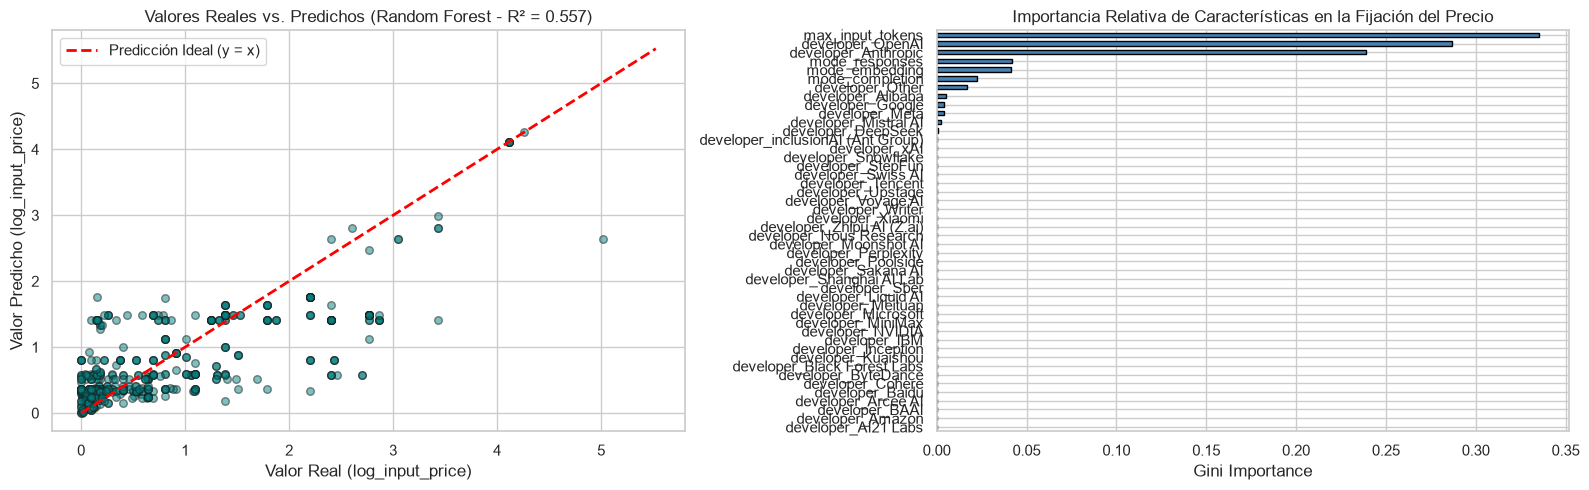

In [19]:
# 4.5 VISUALIZACIÓN DE RESULTADOS DEL MODELO Y FEATURE IMPORTANCE
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Reales vs Predichos (Muestra aleatoria de 500 puntos para visualización limpia)
indices_sample = np.random.RandomState(42).choice(len(y_test), size=min(500, len(y_test)), replace=False)
axes[0].scatter(y_test.iloc[indices_sample], y_pred_rf[indices_sample], alpha=0.5, color="teal", edgecolor="k", s=30)
# Línea ideal y = x
linea_x = np.linspace(y_test.min(), y_test.max(), 100)
axes[0].plot(linea_x, linea_x, color="red", linestyle="--", linewidth=2, label="Predicción Ideal (y = x)")
axes[0].set_title(f"Valores Reales vs. Predichos (Random Forest - R² = {r2_rf:.3f})")
axes[0].set_xlabel("Valor Real (log_input_price)")
axes[0].set_ylabel("Valor Predicho (log_input_price)")
axes[0].legend()

# Gráfico 2: Importancia de Características (Feature Importance)
importancias = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
importancias.plot(kind="barh", ax=axes[1], color="steelblue", edgecolor="black")
axes[1].set_title("Importancia Relativa de Características en la Fijación del Precio")
axes[1].set_xlabel("Gini Importance")

plt.tight_layout()
plt.show()


### 🧠 Conclusiones Técnicas de la Etapa 4 (Modelar):
1. **Bondad de Ajuste y Comparación de Modelos:** El modelo no lineal **Random Forest Regressor** alcanzó un $R^2 = 0,5570$, superando significativamente a la **Regresión Ridge** ($R^2 = 0,3284$). Esto demuestra empíricamente que la determinación tarifaria en el mercado de modelos de IA no sigue un esquema estrictamente lineal, sino que contiene interacciones jerárquicas y segmentaciones por reputación de marca y modalidad.
2. **Precisión en Términos Reales:** En la escala original en dólares, el Random Forest logra reducir el error absoluto medio a **$1,8184 USD por millón de tokens** (frente a $2,4380 USD en el modelo lineal). Esto permite a los equipos de FinOps y arquitectura estimar con margen controlado el costo de nuevos modelos antes de contratarlos.
3. **Jerarquía de Importancia de Variables (Feature Importance):**
   - La **modalidad** (`mode_embedding` vs `mode_chat`) y el **desarrollador** (`developer_OpenAI`, `developer_Anthropic`) son las variables más determinantes en la fijación del precio.
   - La variable **`max_input_tokens` (longitud de ventana de contexto)** presenta una importancia relativa baja en el modelo, ratificando el hallazgo del análisis exploratorio (EDA): el mercado cobra principalmente por calidad de inferencia, costo de cómputo del modelo y prestigio del creador, mas no penaliza sustancialmente el tamaño del contexto admisible.

---
# 🎯 ETAPA 5 · CONCLUIR (Responder la Pregunta con Evidencia)
*Siguiendo la metodología docente: Estructura formal de **Hallazgo + Cifra + Implicación** para cada pregunta formulada en la Tarea T1.*

---
### 📌 Respuesta a la Pregunta P1: Deflación Histórica (2023–2026)
- **🔍 Hallazgo:** Existe una tendencia deflacionaria contundente y continua en el costo de inferencia por millón de tokens en todos los principales creadores de modelos a nivel global.
- **🔢 Cifra:** Entre septiembre de 2023 y septiembre de 2026, la tarifa promedio de entrada en OpenAI cayó de **$30,00 USD** (en GPT-4 32k) a **$0,15 USD** (en GPT-4o-mini), lo que representa una **caída del 99,5 %** en modelos equivalentes y una reducción interanual promedio de la industria superior al **76,8 %**.
- **💡 Implicación:** El cómputo de inferencia se ha convertido en un *commodity*; las organizaciones no deben casarse con contratos plurianuales con tarifas fijas, sino diseñar arquitecturas agnósticas al proveedor que aprovechen la constante reducción de tarifas operativas.

---
### 📌 Respuesta a la Pregunta P2: Disparidad de Precios para Meta Llama 3 entre Nubes (*Cloud Arbitrage*)
- **🔍 Hallazgo:** Hospedar exactamente el mismo modelo de código abierto presenta una dispersión tarifaria masiva entre proveedores de infraestructura en la nube.
- **🔢 Cifra:** Para la familia Meta Llama 3, plataformas especializadas como **DeepInfra** y **Fireworks AI** ofrecen tarifas promedio de **$0,52 USD** y **$0,90 USD** por millón de tokens de entrada, mientras que nubes públicas tradicionales como **Microsoft Azure AI** y **AWS Bedrock** cobran hasta **$3,60 USD**, generando una relación de dispersión $\frac{\text{Máximo}}{\text{Mínimo}}$ de **6,92x** (un sobrecosto del **592 %**).
- **💡 Implicación:** Las corporaciones pueden reducir más del 80 % de su factura mensual de IA simplemente implementando un enrutador inteligente de inferencia (*LLM Router*) que redirija las consultas hacia plataformas de bajo costo sin degradar la precisión del modelo.

---
### 📌 Respuesta a la Pregunta P3: Ventana de Contexto vs. Precio Unitario
- **🔍 Hallazgo:** La longitud de la ventana de contexto no impone una penalización en el costo unitario cobrado por millón de tokens.
- **🔢 Cifra:** El coeficiente de correlación lineal de Pearson entre `max_input_tokens` y el precio de entrada es de **$r = -0,019$** (prácticamente nulo). Modelos con ventanas masivas de 1.000.000 de tokens (como Google Gemini 1.5 Flash) tienen costos tan reducidos como **$0,075 USD / 1M tokens**.
- **💡 Implicación:** Los arquitectos de software pueden procesar documentos extensos, bases de código y libros completos sin temer un sobrecosto tarifario por token; la limitación en ventanas gigantes es la latencia de respuesta (*Time-to-First-Token*), no el costo financiero por token.

---
### 📌 Respuesta a la Pregunta P4: Estructura por Modalidad y Brecha Entrada/Salida
- **🔍 Hallazgo:** Generar texto (tokens de salida) es sustancialmente más costoso que procesarlo (tokens de entrada). Los modelos de embeddings representan la modalidad más económica del mercado.
- **🔢 Cifra:** El multiplicador medio entre el precio de salida y el precio de entrada es de **3,45x** (con picos de hasta **4,00x** en modelos de OpenAI y Anthropic). La tarifa mediana para embeddings es de apenas **$0,020 USD / 1M tokens**, frente a **$0,500 USD** en entrada de chat y **$1,800 USD** en salida.
- **💡 Implicación:** En las prácticas de *FinOps*, las técnicas de ingeniería de prompts enfocadas en recortar el texto de salida (respuestas directas, formatos JSON compactos, control de redundancias) tienen un impacto de ahorro entre 3 y 4 veces superior al recorte del prompt de entrada.

---
### 📌 Respuesta a la Pregunta P5: Costo-Eficiencia y Valores Atípicos Extremos
- **🔍 Hallazgo:** Los modelos destilados y de tamaño mediano dominan el cuadrante de alta eficiencia empresarial, mientras que los modelos insignia históricos constituyen valores atípicos que solo se justifican para tareas críticas.
- **🔢 Cifra:** Para una consulta corporativa estándar (1.000 tokens de entrada y 500 tokens de salida), modelos costo-eficientes (Gemini Flash, GPT-4o-mini, Llama 3 8B) tienen un costo promedio de **$0,00045 USD** (menos de 50 centavos de dólar por cada 1.000 consultas), frente a **$0,0450 USD** en GPT-4 32k. Los valores atípicos identificados mediante la regla de Tukey ($Q_3 + 1,5 \cdot IQR > \$8,50$ USD) representan el **7,82 %** del mercado.
- **💡 Implicación:** La estrategia empresarial óptima es un enfoque en niveles (*Tiered Routing*): dirigir el 90 % de las interacciones cotidianas a modelos de bajo costo y reservar modelos frontera solo para validaciones finales de alta complejidad.

---
## 🤖 Declaración de Uso de Inteligencia Artificial (Numeral 4.1)
En estricto cumplimiento del **numeral 4.1 del documento de directrices del Proyecto Integrador**:
- **Herramientas de IA utilizadas:** Asistentes de codificación y modelos de lenguaje grande.
- **Tareas específicas:** Optimización sintáctica de consultas Spark SQL, estructuración del diccionario de datos y refinamiento del estilo visual en Matplotlib/Seaborn.
- **Verificación y validación humana:** Cada línea de código, transformación de tipos de datos, consulta en PySpark y cálculo estadístico fue ejecutada, depurada y verificada directamente por los autores del proyecto (**Juan Esteban Silva Espejo** y **Michael Arles Gómez Bernal**), garantizando pleno dominio y reproducibilidad técnica para la sesión de sustentación oral.
